# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AFODataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 2912


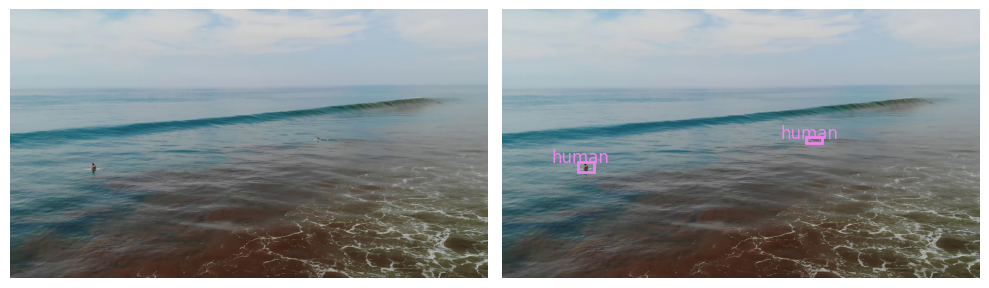

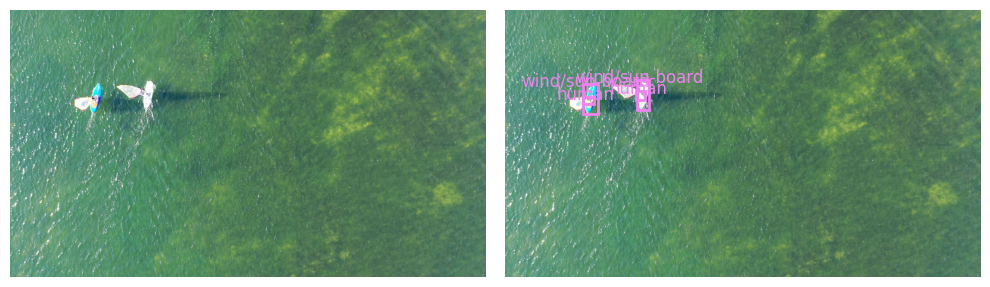

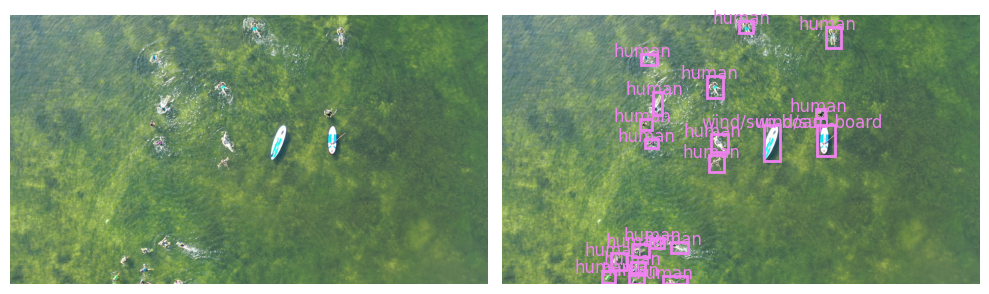

In [ ]:
dataset_config = {
    "data_dir": "./data/AFO/images/",
    "annotation_dir": "./data/AFO/annotations/6categories/",
}
dataset = AFODataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

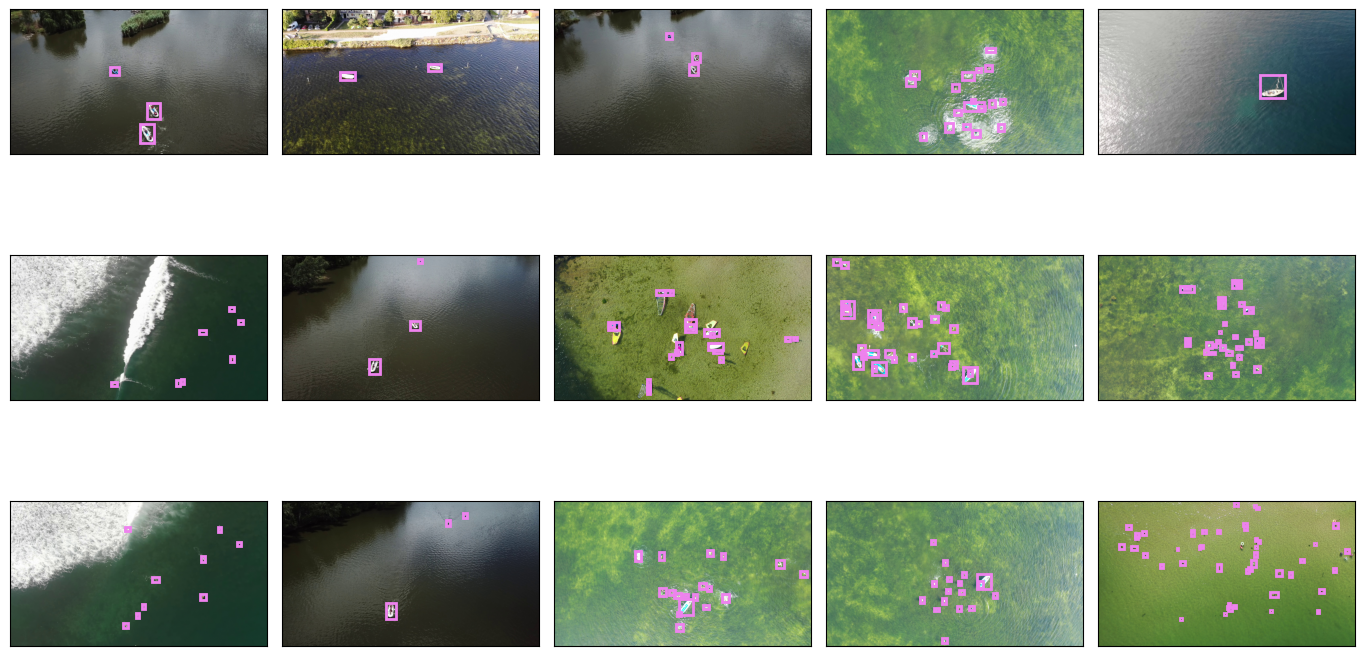

In [26]:
dataset.show_batch(15);

In [26]:
dataset.data_distribution_table()

,Label,Count
0,human,33174
1,wind/sup-board,3922
2,boat,702
3,buoy,587
4,sailboat,160
5,kayak,1446


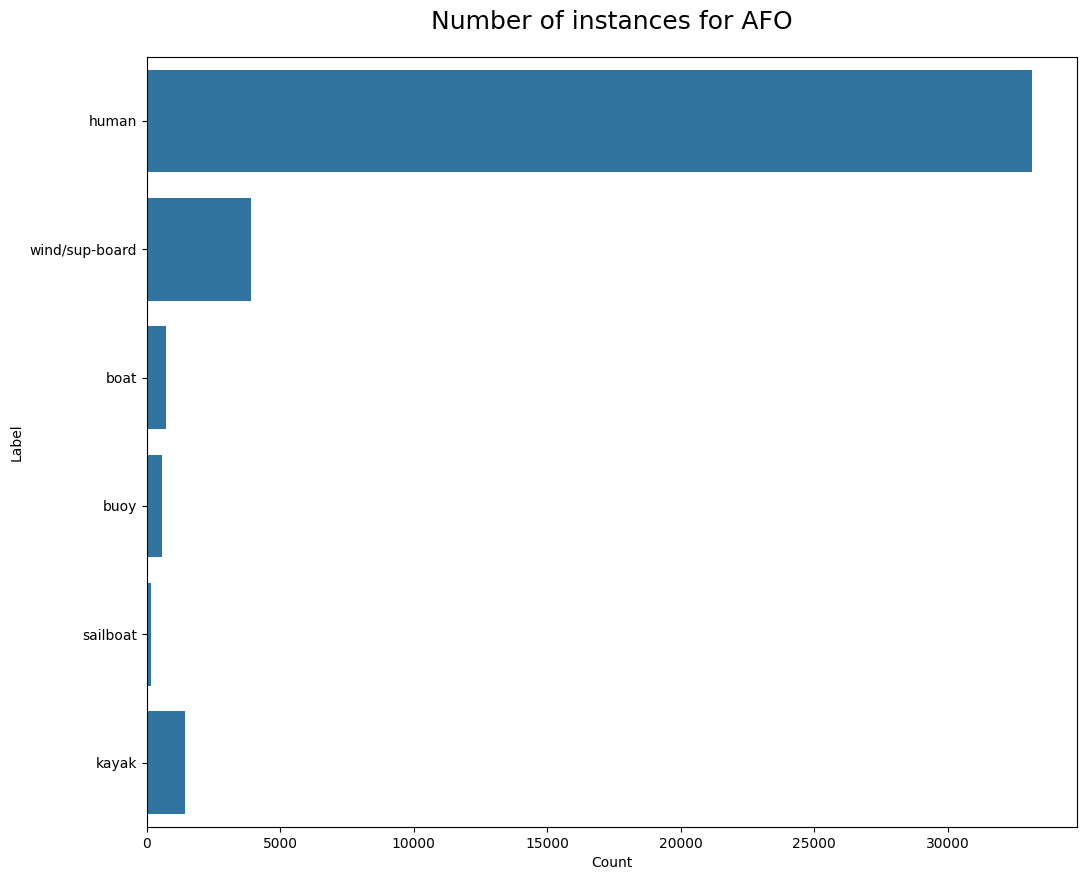

In [27]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/AFO/images/",
    "annotation_dir": "./data/AFO/annotations/6categories/",
    "csv_file": "./data/AFO/train.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = AFODataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 2066


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/AFO/experiments/"
model_config = {
    "num_classes": 7,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 11:59:37,355 INFO Starting training.
training: 100%|██████████| 259/259 [01:25<00:00,  3.04it/s]
2025-05-22 12:01:02,953 INFO epoch: 1, time: 85, loss:  0.53881
testing on train set: 100%|██████████| 259/259 [00:55<00:00,  4.66it/s]
2025-05-22 12:02:19,001 INFO map:0.45659199357032776, map_50:0.8716533780097961, map_75:0.4446496069431305, map_small:0.464495986700058, map_medium:0.5700593590736389, map_large:0.5503638982772827, mar_1:0.2263832837343216, mar_10:0.5091329216957092, mar_100:0.5483422875404358, mar_small:0.5497149229049683, mar_medium:0.6455671787261963, mar_large:0.6434267163276672, map_per_class:tensor(0.2807), tensor(0.5958), tensor(0.4958), tensor(0.2470), tensor(0.5066), tensor(0.6136), mar_100_per_class:tensor(0.3876), tensor(0.6743), tensor(0.6156), tensor(0.3369), tensor(0.5800), tensor(0.6956), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32), tensor(5, dtype=torch.int32), tens

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/AFO/images/",
    "annotation_dir": "./data/AFO/annotations/6categories/",
    "csv_file": "./data/AFO/validation.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = AFODataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/AFO/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 330


2025-05-22 12:39:31,099 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AFO/experiments/checkpoint.pth.tar
2025-05-22 12:39:31,456 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AFO/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 42/42 [00:09<00:00,  4.46it/s]


[{'map': 0.5605981349945068,
  'map_50': 0.8998382687568665,
  'map_75': 0.6121010780334473,
  'map_small': 0.5717942118644714,
  'map_medium': 0.6161469221115112,
  'map_large': 0.699999988079071,
  'mar_1': 0.27060097455978394,
  'mar_10': 0.5703664422035217,
  'mar_100': 0.6268056035041809,
  'mar_small': 0.6308157444000244,
  'mar_medium': 0.6610552072525024,
  'mar_large': 0.699999988079071,
  'map_per_class': [tensor(0.4626),
   tensor(0.6966),
   tensor(0.6222),
   tensor(0.3344),
   tensor(0.6395),
   tensor(0.6083)],
  'mar_100_per_class': [tensor(0.5394),
   tensor(0.7630),
   tensor(0.6925),
   tensor(0.4270),
   tensor(0.6588),
   tensor(0.6801)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32),
   tensor(6, dtype=torch.int32)]}]

## Predictions

2025-05-22 12:39:51,794 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AFO/experiments/checkpoint.pth.tar
2025-05-22 12:39:52,129 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AFO/experiments/checkpoint.pth.tar at epoch 11


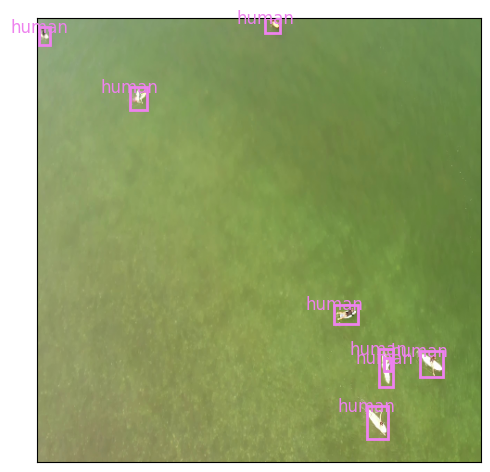

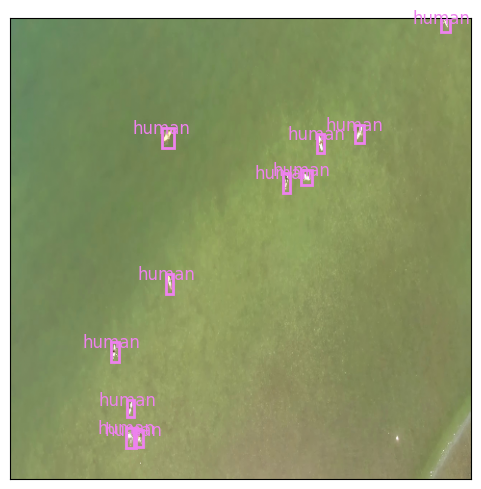

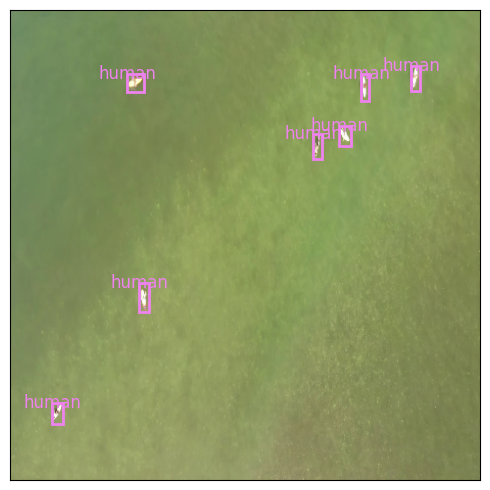

In [ ]:
model_config = {
    "num_classes": 7,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/AFO/experiments/checkpoint.pth.tar"
labels = ["no-data","human","wind/sup-board","boat","buoy","sailboat","kayak"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/AFO/test.txt"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = file.readlines()
    for lines in csvFile:
        test_list.append(lines[: -1])

image = image_loader('./data/AFO/images/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/AFO/images/' + test_list[1])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/AFO/images/' + test_list[10])
fig = model.detect_objects(image, labels, transform)